# 1. Знакомство с данными и их качество

Датасет: Selent, Patikorn, Heffernan (2016), 22 эксперимента в ASSISTments. Одна строка - один ученик в одном задании.
Все агрегаты считаются SQL-запросами из `sql/columns.sql` и `sql/quality.sql` над вьюхами из `sql/staging.sql`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src import db

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
con = db.connect()

## Колонки

Источник: «ст. 1» - статья о датасете, «ст. 2» - раздел Variables второй статьи, «предположение» - вывод
по названию и данным. Формулы с пометкой «проверено» сходятся во всех строках (запрос `invalid_values` ниже).
Тип - как его вывел DuckDB, пропуски - доля NULL, где NULL - пустое поле или `N/A`.

In [2]:
MEANING = {
    "problem_set": ("ID задания Skill Builder, он же ID эксперимента (22 значения)", "предположение"),
    "problem_set_name": ("название задания с кодом стандарта", "предположение"),
    "User ID": ("ID ученика", "предположение"),
    "InferredCondition": ("группа C/E, восстановленная по решённым задачам; в xlsx колонка называется Condition", "ст. 1, 2"),
    "ExperiencedCondition": ("увидел ли ученик своё условие", "предположение по названию и ст. 1"),
    "Could See Video": ("итог вопроса-проверки видео, 1/0; N/A вне экспериментов с видео", "ст. 1"),
    "Prior Problem Count": ("сколько задач ученик решил до эксперимента", "предположение"),
    "Prior Correct Count": ("сколько из них верно", "предположение"),
    "Prior Percent Correct": ("доля верных до эксперимента = Correct / Problem Count (проверено)", "ст. 2"),
    "Class ID": ("ID класса", "предположение"),
    "Class Section ID": ("ID секции класса", "предположение"),
    "Class Grade": ("год обучения: 5-12 или Freshmen...Senior", "предположение"),
    "Teacher ID": ("ID учителя", "предположение"),
    "Guessed Gender": ("пол, угаданный по имени: Male, Female, Unknown", "ст. 2"),
    "Birthyear": ("год рождения", "предположение"),
    "school_id": ("ID школы", "предположение"),
    "District ID": ("ID школьного округа", "предположение"),
    "State ID": ("ID штата", "ст. 2"),
    "Prior Assignments Assigned": ("сколько заданий было назначено до эксперимента", "предположение"),
    "Prior Assignment Count": ("сколько заданий ученик начал", "предположение"),
    "Prior Completion Count": ("сколько заданий завершил", "предположение"),
    "Prior Percent Completion": ("доля завершённых Skill Builder в том же классе = Completion / Assignment Count (проверено)", "ст. 2"),
    "Prior Class Percent Completion": ("та же доля в среднем по классу", "предположение"),
    "Z-Scored Mastery Speed": ("прошлый mastery speed, z-оценка внутри класса", "ст. 2"),
    "Prior Homework Assigned": ("сколько домашних заданий назначено", "предположение"),
    "Prior Homework Count": ("сколько домашних заданий начал", "предположение"),
    "Prior Homework Completion Count": ("сколько домашних заданий завершил", "предположение"),
    "Prior Homework Percent Completion": ("доля завершённых домашних = Completion / Homework Count (проверено)", "ст. 2"),
    "Prior Class Homework Percent Completion": ("та же доля в среднем по классу", "предположение"),
    "Z-Scored HW Mastery Speed": ("то же, что Z-Scored Mastery Speed, только по домашним", "ст. 2"),
    "complete": ("завершил ли задание", "ст. 2"),
    "ProblemCount": ("задач в этом задании; у завершивших это mastery speed", "ст. 1, 2; у незавершивших - предположение"),
    "log(count)": ("log10(ProblemCount), только при complete = 1 (проверено)", "ст. 2"),
}

profile = db.run(con, "columns.sql", "profile")
profile["meaning"] = profile.column_name.map(lambda c: MEANING[c][0])
profile["source"] = profile.column_name.map(lambda c: MEANING[c][1])
profile[["column_name", "meaning", "source", "column_type", "null_percentage"]]

,column_name,meaning,source,column_type,null_percentage
0,problem_set,"ID задания Skill Builder, он же ID эксперимент...",предположение,BIGINT,0.00
1,problem_set_name,название задания с кодом стандарта,предположение,VARCHAR,0.00
2,User ID,ID ученика,предположение,BIGINT,0.00
3,InferredCondition,"группа C/E, восстановленная по решённым задача...","ст. 1, 2",VARCHAR,0.00
4,ExperiencedCondition,увидел ли ученик своё условие,предположение по названию и ст. 1,BOOLEAN,0.00
5,Could See Video,"итог вопроса-проверки видео, 1/0; N/A вне эксп...",ст. 1,BIGINT,64.45
6,Prior Problem Count,сколько задач ученик решил до эксперимента,предположение,BIGINT,2.15
7,Prior Correct Count,сколько из них верно,предположение,BIGINT,2.15
8,Prior Percent Correct,доля верных до эксперимента = Correct / Proble...,ст. 2,DOUBLE,2.15
9,Class ID,ID класса,предположение,BIGINT,0.00


В трёх строковых колонках значения обёрнуты в лишние кавычки, а пропуск записан строкой. Такие строки
NULL не ловит, считаю их отдельно. В `staging.sql` кавычки снимаются, `N/A` и пустая строка становятся NULL,
а `Uknown` исправляется на `Unknown`.

In [3]:
db.run(con, "columns.sql", "string_placeholders")

,class_grade_na,birthyear_empty,gender_uknown,n
0,3806,19,4744,14947


Флагов `... Valid` из второй статьи в файле нет: там их построили сами авторы. Здесь отсутствие значения - это NULL.

## Сверка со статьёй

В статье о датасете: 22 эксперимента, 8 297 уникальных учеников, 102 252 задачи, 32 колонки (на сайте датасета - 33).

In [4]:
overview = db.run(con, "quality.sql", "overview")
paper = {"n_experiments": 22, "n_users": 8297, "n_problems": 102252, "n_columns": 32}
file_ = {
    "n_experiments": overview.n_experiments[0],
    "n_users": overview.n_users[0],
    "n_problems": int(overview.n_problems[0]),
    "n_columns": len(profile),
}
pd.DataFrame({"paper": paper, "file": file_}).assign(diff=lambda d: d.file - d.paper)

,paper,file,diff
n_experiments,22,22,0
n_users,8297,8205,-92
n_problems,102252,97798,-4454
n_columns,32,33,1


In [5]:
overview[["n_rows", "n_users_multi", "share_users_multi"]]

,n_rows,n_users_multi,share_users_multi
0,14947,2751,0.335283


Около трети учеников участвовали больше чем в одном эксперименте - как и пишут авторы.

В Table 1 статьи эксперименты пронумерованы, но без `problem_set`, поэтому сверить файл со статьёй
по каждому эксперименту нельзя. Сверяю только сумму учеников по экспериментам.

In [6]:
paper_students = [1204, 695, 381, 627, 1864, 457, 515, 540, 402, 545, 412,
                  335, 497, 704, 523, 136, 428, 745, 1330, 1917, 429, 426]
per_exp = db.run(con, "quality.sql", "per_experiment")
print("сумма учеников по Table 1:", sum(paper_students), "строк в файле:", overview.n_rows[0])

сумма учеников по Table 1: 15112 строк в файле: 14947


## CSV и xlsx

Сравниваю каждую ячейку по ключу (problem_set, User ID). Разница в форматировании не считается: точность
float, `TRUE` и `1`, пустая строка и NULL.

In [7]:
xlsx = db.run(con, "quality.sql", "xlsx_diff")
xlsx[["only_csv", "only_xlsx", "n_diff"]].sum()

only_csv     0
only_xlsx    0
n_diff       0
dtype: int64

## Группы и дубли

In [8]:
per_exp[["experiment_id", "experiment_name", "n_rows", "n_c", "n_e"]]

,experiment_id,experiment_name,n_rows,n_c,n_e
0,226210,Multiplying Mixed Numbers 5.NF.B.4a EX,1185,607,578
1,237447,Understanding Vocabulary About Circles G-C.A.2 EX,692,329,363
2,241501,Equivalent Expressions 6.EE.B.4 EX,381,188,193
3,241622,Writing Inequalities from Situations 6.EE.B8 EX,627,338,289
4,243393,Dividing Mixed Numbers 6.NS.A.1-Ex,1797,910,887
5,246482,Finding Expected Value SS.MD.B.5 EX,457,225,232
6,246627,Conditional Probability SS-CP.A.3 EX,514,279,235
7,246647,Permutations and Combinations SS-CP.B.2 EX,538,264,274
8,250476,Basic Logarithm Manipulation F-BF.B.5 EX,402,193,209
9,255116,Properties of Exponents 8.EE.A.1 EX,534,258,276


In [9]:
db.run(con, "quality.sql", "duplicates").T

,0
full_duplicates,0
user_twice_in_experiment,0
users_in_both_groups_across_experiments,1903
same_but_user_groups,30
same_but_user_rows,67
same_but_user_groups_without_history,26


Полных дублей нет, и ни один ученик не встречается в одном эксперименте дважды. Есть строки, которые совпадают
во всём, кроме `User ID`: почти все у учеников без истории, у которых все ковариаты пустые. Это не дубли,
а совпадение, и я их оставляю.

## Некорректные значения

In [10]:
db.run(con, "quality.sql", "invalid_values")

,check_name,n_rows
0,grp_not_c_e,0
1,complete_not_binary,0
2,video_not_binary,0
3,problem_count_negative,0
4,share_out_of_0_1,0
5,correct_gt_problems,0
6,completed_gt_started,0
7,started_gt_assigned,0
8,hw_completed_gt_started,0
9,hw_started_gt_assigned,1


Год рождения вне 1990-2008 считаю неправдоподобным: в 2013-2015 годах так выходит ученик 4-12 класса,
плюс-минус несколько лет. `Birthyear` и `Class Grade` в анализе не используются.

## Кто не увидел условие

Условие не записывалось при рандомизации, его восстановили по задачам. Если группу проставляли только тем,
кто дошёл до отличающихся задач, у не увидевших условие группа должна быть пустой или почти всегда одной и той же.

In [11]:
exp_by_grp = db.run(con, "quality.sql", "experienced_by_group")
exp_by_grp["share_c_among_not_exp"] = exp_by_grp.not_exp_c / (exp_by_grp.not_exp_c + exp_by_grp.not_exp_e)
exp_by_grp["share_c_overall"] = exp_by_grp.n_c / (exp_by_grp.n_c + exp_by_grp.n_e)
exp_by_grp

,experiment_id,n_c,n_e,not_exp_c,not_exp_e,share_not_exp_c,share_not_exp_e,share_c_among_not_exp,share_c_overall
0,226210,607,578,210,213,0.345964,0.368512,0.496454,0.512236
1,237447,329,363,0,0,0.000000,0.000000,NaN,0.475434
2,241501,188,193,50,58,0.265957,0.300518,0.462963,0.493438
3,241622,338,289,0,0,0.000000,0.000000,NaN,0.539075
4,243393,910,887,0,0,0.000000,0.000000,NaN,0.506400
5,246482,225,232,0,0,0.000000,0.000000,NaN,0.492341
6,246627,279,235,0,0,0.000000,0.000000,NaN,0.542802
7,246647,264,274,0,0,0.000000,0.000000,NaN,0.490706
8,250476,193,209,98,106,0.507772,0.507177,0.480392,0.480100
9,255116,258,276,0,0,0.000000,0.000000,NaN,0.483146


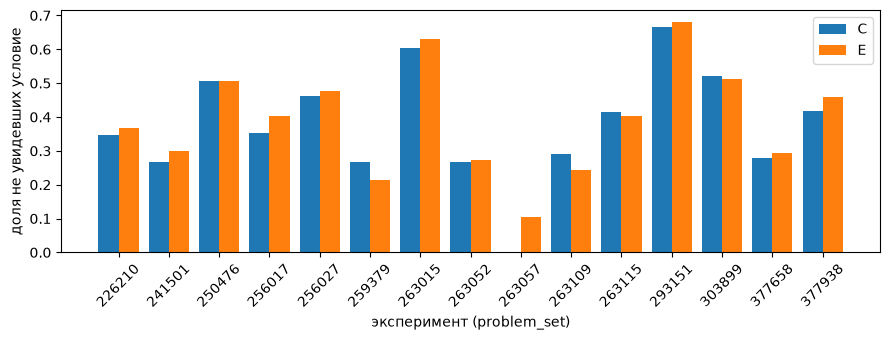

In [12]:
d = exp_by_grp[exp_by_grp.not_exp_c + exp_by_grp.not_exp_e > 0]
x = range(len(d))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar([i - 0.2 for i in x], d.share_not_exp_c, width=0.4, label="C")
ax.bar([i + 0.2 for i in x], d.share_not_exp_e, width=0.4, label="E")
ax.set_xticks(list(x), d.experiment_id, rotation=45)
ax.set_xlabel("эксперимент (problem_set)")
ax.set_ylabel("доля не увидевших условие")
ax.legend()
plt.tight_layout()

In [13]:
db.run(con, "quality.sql", "experienced_outcomes")

,experiment_id,experienced,n,completion,median_problems,share_done_in_3,share_quit_by_2
0,226210,False,423,0.737589,3.0,0.737589,0.257683
1,226210,True,762,0.614173,5.0,0.000000,0.212598
2,241501,False,108,0.851852,9.0,0.000000,0.000000
3,241501,True,273,0.879121,13.0,0.000000,0.000000
4,250476,False,204,0.980392,2.0,0.980392,0.019608
5,250476,True,198,0.843434,8.0,0.000000,0.015152
6,256017,False,156,0.916667,2.0,0.916667,0.083333
7,256017,True,256,0.832031,8.0,0.000000,0.007812
8,256027,False,157,0.968153,2.0,0.968153,0.031847
9,256027,True,178,0.848315,7.0,0.000000,0.005618


## Проверка видео

In [14]:
db.run(con, "quality.sql", "video_check")

,experiment_id,grp,n,n_checked,n_cannot_see,share_cannot_see
0,250476,C,193,193,46,0.238342
1,250476,E,209,209,46,0.220096
2,256017,C,199,199,30,0.150754
3,256017,E,213,213,30,0.140845
4,256027,C,165,165,30,0.181818
5,256027,E,170,170,23,0.135294
6,259379,C,239,239,36,0.150628
7,259379,E,258,258,58,0.224806
8,263015,C,360,360,46,0.127778
9,263015,E,344,344,62,0.180233


## Сколько задач нужно для завершения

При правиле «три подряд» завершивший не может решить меньше трёх задач.

In [15]:
db.run(con, "quality.sql", "completion_rule")

,experiment_id,has_video_check,n_done,min_done,min_done_c,min_done_e,n_done_2,n_done_3,n_done_2_c,n_done_2_e
0,226210,False,780,3,3,3,0,312,0,0
1,237447,False,672,3,3,3,0,183,0,0
2,241501,False,332,8,8,8,0,0,0,0
3,241622,False,540,8,8,8,0,0,0,0
4,243393,False,1303,3,3,3,0,616,0,0
5,246482,False,337,3,3,3,0,149,0,0
6,246627,False,365,3,3,3,0,124,0,0
7,246647,False,455,3,3,3,0,276,0,0
8,250476,True,367,2,2,2,101,99,44,57
9,255116,False,432,7,7,8,0,0,0,0


In [16]:
db.run(con, "quality.sql", "done_in_2_by_video")

,could_see_video,n_done,n_done_2,n_done_3,share_done_2
0,0,539,6,176,0.011132
1,1,2698,695,547,0.257598


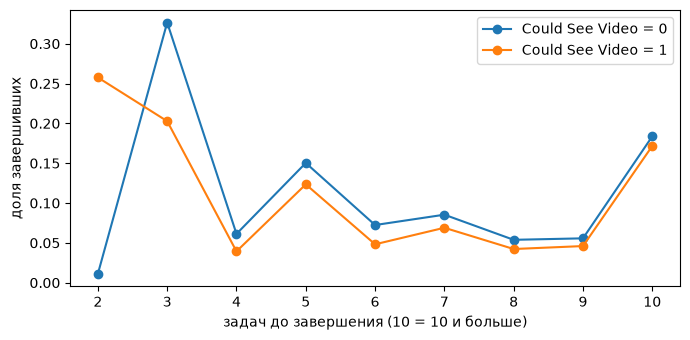

In [17]:
dist = db.run(con, "quality.sql", "done_distribution_by_video")
dist["share"] = dist.n / dist.groupby("could_see_video").n.transform("sum")
fig, ax = plt.subplots(figsize=(7, 3.5))
for v, g in dist.groupby("could_see_video"):
    ax.plot(g.problem_count, g.share, marker="o", label=f"Could See Video = {v}")
ax.set_xlabel("задач до завершения (10 = 10 и больше)")
ax.set_ylabel("доля завершивших")
ax.legend()
plt.tight_layout()

## ProblemCount = 0

In [18]:
db.run(con, "quality.sql", "zero_problems")

,experiment_id,complete,experienced,n
0,226210,0,False,24
1,243393,0,True,22


## Итог

- В файле 14 947 строк, 22 эксперимента, 8 205 учеников и 33 колонки. Значения в CSV и xlsx совпадают,
  отличается только имя колонки группы: `InferredCondition` в CSV и `Condition` в xlsx.
- Со статьёй файл расходится. Учеников 8 205 против 8 297, задач 97 798 против 102 252, строк 14 947 против
  15 112 по Table 1. Предположение: файлы на сайте обновлены 29.09.2016 (CSV V3, xlsx V7), а статья написана
  раньше, то есть это другая версия данных.
- Дублей нет: ни полных, ни одного ученика дважды в эксперименте. 67 строк в 30 группах совпадают во всём, кроме
  `User ID`, и в 26 группах из 30 у учеников нет истории. Это совпадение, а не дубли.
- Производные колонки сходятся с формулами во всех строках. Нашлась одна строка, где начатых домашних заданий
  больше, чем назначенных. `Birthyear` пуст в 19 строках, в 364 строках год вне 1990-2008. `Class Grade` пуст
  в 3 806 строках и записан словами в 455. Пол не угадан у 4 744 учеников. Эти колонки в анализе не используются.
- `ExperiencedCondition`. В 8 экспериментах условие увидели все. В остальных 14 не увидели от 10 до 68% учеников
  группы. Среди не увидевших группы делятся так же, как среди всех, кроме эксперимента 263057: там все 7 не увидевших
  в группе E. Значит, группа известна и тем, кто условие не увидел. Не увидевшие в основном решили задание за
  три задачи без ошибок или бросили на первых двух. Похоже, условие срабатывает на ошибку или просьбу о помощи,
  как триггер в онлайн-экспериментах. Какую выборку брать для анализа, решаем на этапе 2.
- Проверка видео есть в 9 экспериментах, в обеих группах и у всех учеников. В эксперименте 263052 видео видят все.
  В экспериментах 259379 и 263015 доля не видящих видео в группах разная (15,1% и 22,5%, 12,8% и 18,0%), проверю на этапе 2.
- Завершение за 2 задачи встречается только в 8 экспериментах с проверкой видео (во всех, кроме 293151): 701 строка,
  в обеих группах примерно поровну. Среди тех, кто видит видео, за 2 задачи завершили 25,8%, среди не видящих -
  1,1%. Предположение: верный ответ на вопрос-проверку засчитывается как первая задача серии, но в `ProblemCount`
  не входит. Это не правило «два подряд» и не повреждённые строки, я их оставляю. Mastery speed в этих экспериментах
  занижен на единицу, но одинаково в обеих группах.
- В экспериментах 241501, 241622, 255116 и 263057 завершившие решили минимум 7-8 задач, значит, правило завершения там другое
  (предположение). Найти повреждённые строки так, как во второй статье (завершил не с той длиной серии), по этому
  файлу нельзя: последовательности ответов в нём нет.
- `ProblemCount = 0` у 46 строк, все с `complete = 0`. 24 из них в эксперименте 226210, эти ученики не увидели условие
  и, видимо, не начали задание. 22 в эксперименте 243393, и у них `ExperiencedCondition = TRUE`. Предположение: там
  условие показывается до первой задачи. Строк с `complete = 1` и нулём задач нет.